In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
from pathlib import Path
import sys

import numpy as np
from PIL import Image
from matplotlib import pyplot as plt

cwd = Path.cwd()
PROJECT_ROOT = cwd.parent if cwd.name == "notebooks" else cwd
sys.path.insert(0, str(PROJECT_ROOT))

In [4]:
from weed_detector.config import load_config

config = load_config()

## 1. Download dataset

In [5]:
from weed_detector.data.download import download_dataset

raw_dir = config["paths"]["raw_dir"]
download_dataset(raw_dir=raw_dir) 

[INFO] Dataset found at '/home/adrian/projects/weed-detector/data/raw'


## 2. Inspect dataset

In [7]:
# Check 1: File types
data_dir = Path(config["paths"]["raw_data_dir"])
data_names = [p.name for p in data_dir.iterdir()]
file_types = set()
for n in data_names:
    file_types.add(n.split(".")[1])
print(f"File types found: {file_types}")

File types found: {'txt', 'jpeg'}


Image shapes found: {(512, 512, 3)}
Image dtypes found: {dtype('uint8')}
Value min: 0; value max: 255


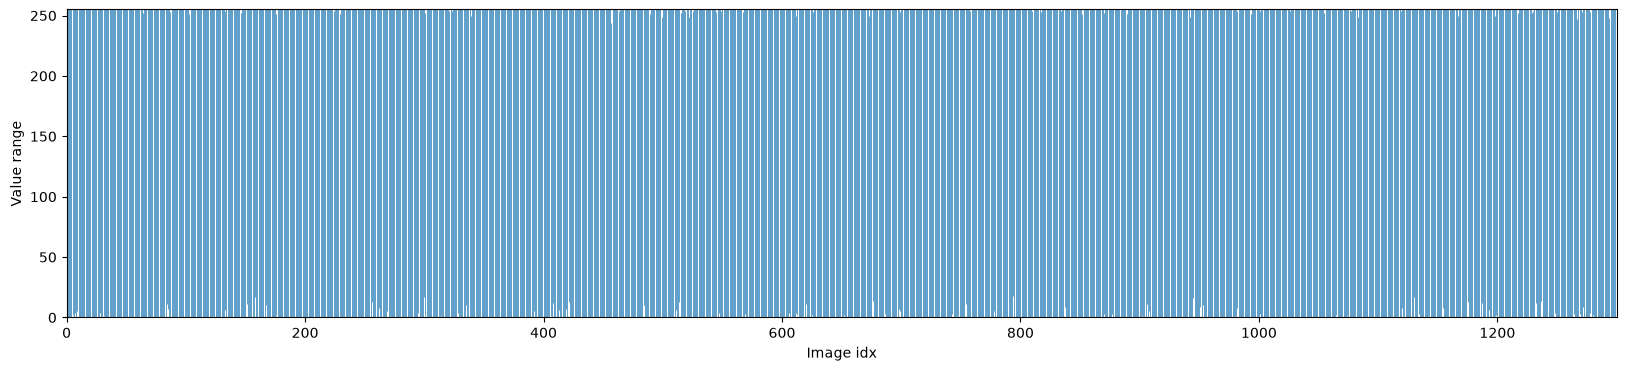

In [8]:
# Check 2: img stats
data_dir = Path(config["paths"]["raw_data_dir"])
img_paths = list(data_dir.glob("*.jpeg"))
img_shapes = set()
img_dtypes = set()
img_mins = []
img_maxs = []
for img_path in img_paths:
    img = np.asarray(Image.open(img_path))
    img_shapes.add(img.shape)
    img_dtypes.add(img.dtype)
    img_mins.append(img.min())
    img_maxs.append(img.max())

print(f"Image shapes found: {img_shapes}")
print(f"Image dtypes found: {img_dtypes}")
print(f"Value min: {min(img_mins)}; value max: {max(img_maxs)}")

fig = plt.figure(figsize=(20,4))
n_imgs = len(img_paths)
plt.vlines(x=range(n_imgs),
           ymin=img_mins,
           ymax=img_maxs,
           linewidth=0.5)
plt.xlim(0, n_imgs)
plt.ylim(min(img_mins), max(img_maxs))
plt.xlabel("Image idx")
plt.ylabel("Value range");


Bbox global min vals (x_c, y_c, w, h):
 [0.03418  0.038086 0.041016 0.037109]
Bbox global max vals (x_c, y_c, w, h):
 [0.975586 0.96582  0.998047 0.998047]
Bbox global xmin: 0.0019524999999999681
Bbox global ymin: 0.0019524999999999681
Bbox global xmax: 1.0000005
Bbox global ymax: 1.0000005
Counts per class: {0: 1212, 1: 860}


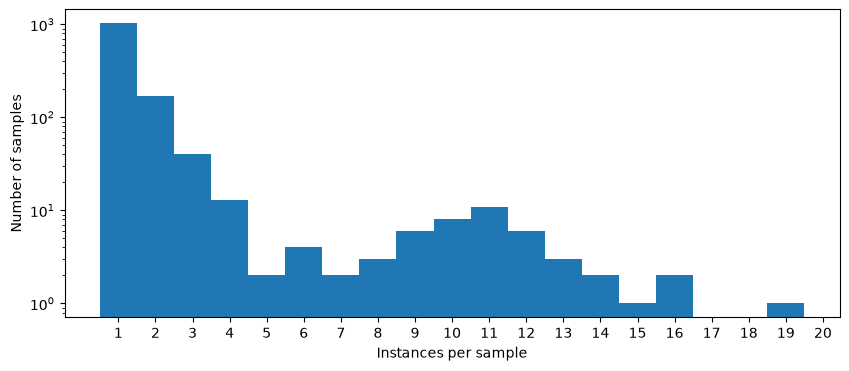

In [9]:
# Check 3: bbox + labels
from weed_detector.utils.labels import get_lbl_arrays

data_dir = Path(config["paths"]["raw_data_dir"])
lbl_paths = list(data_dir.glob("*.txt"))

all_classes = []
all_bbxs = []
instances_per_sample = []


for lbl_path in lbl_paths:
    classes, bbxs = get_lbl_arrays(lbl_path)

    all_classes.append(classes)
    all_bbxs.append(bbxs)
    instances_per_sample.append(len(classes))

all_classes = np.concatenate(all_classes)  
all_bbxs = np.concatenate(all_bbxs, axis=0)        
instances_per_sample = np.array(instances_per_sample)

x_c, y_c, w, h = all_bbxs[:, 0], all_bbxs[:, 1], all_bbxs[:, 2], all_bbxs[:, 3]
x_mins, x_maxs = x_c - w / 2, x_c + w / 2
y_mins, y_maxs = y_c - h / 2, y_c + h / 2


print(f"Bbox global min vals (x_c, y_c, w, h):\n {all_bbxs.min(axis=0)}")
print(f"Bbox global max vals (x_c, y_c, w, h):\n {all_bbxs.max(axis=0)}")
print(f"Bbox global xmin: {min(x_mins)}")
print(f"Bbox global ymin: {min(y_mins)}")
print(f"Bbox global xmax: {max(x_maxs)}")   
print(f"Bbox global ymax: {max(y_maxs)}") 

unique, counts = np.unique(all_classes, return_counts=True)
class_counts = dict(zip(unique.tolist(), counts.tolist()))
print(f"Counts per class: {class_counts}")

fig = plt.figure(figsize=(10,4))
plt.hist(x=instances_per_sample, 
         bins=range(1, instances_per_sample.max() + 2), 
         align="left",
         log=True)
plt.xlabel("Instances per sample")
plt.ylabel("Number of samples")
plt.xticks(range(1, instances_per_sample.max() + 2))
plt.show()

## 3. Inspect data visually

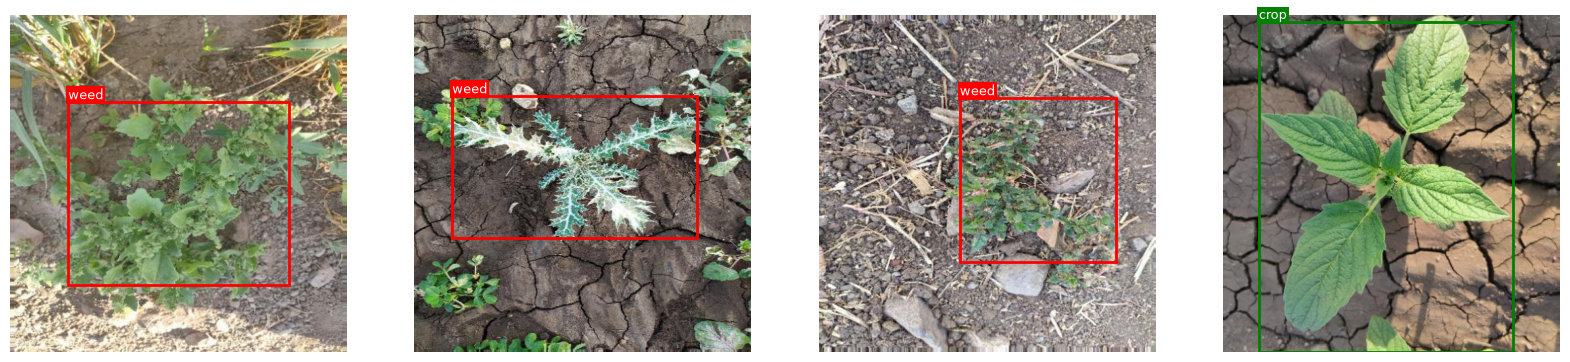

In [11]:
import random 
from weed_detector.visualization.plots import visualize_sample


def inspect_rnd_samples(
        raw_dir: str | Path,
        raw_data_dir: str | Path,
        k: int = 4,
        ) -> None:
    """
    Visualize k random data-label pairs
    """
    
    # Get random image path
    raw_data_dir = Path(raw_data_dir)
    img_paths = list(raw_data_dir.glob("*.jpeg"))
    rnd_img_paths = random.sample(img_paths, k)

    # Get class mapping
    classes_path = Path(raw_dir) / "classes.txt"
    classes = open(classes_path, "r").read().split()
    idx_to_class = {i: c for i,c in enumerate(classes)}
 
    _, axs = plt.subplots(1,k,figsize=(5*k,5))

    for img_path, ax in zip(rnd_img_paths, axs):
        # Get label path
        img_id = img_path.stem
        lbl_path = raw_data_dir / (img_id +".txt")

        visualize_sample(img_path, lbl_path, idx_to_class, ax)


inspect_rnd_samples(raw_dir=config["paths"]["raw_dir"],
                    raw_data_dir=config["paths"]["raw_data_dir"])